# Visualization of Working Hours × Life Satisfaction by Prefecture

Working hours (Ministry of Health, Labour and Welfare, e-Stat Social Life Statistics Indicators, 2024 / Monthly Actual Working Hours for Men) and life satisfaction (Sony Life Insurance, "47-Prefecture Life Awareness Survey 2024" scored on a 10-point scale) are color-coded on a map of Japan, and the relationship between the two is examined using a scatter plot

# 都道府県別 労働時間 × 生活満足度 の可視化

労働時間（厚労省・e-Stat 社会生活統計指標 2024年度／月間実労働時間数・男性）と、生活満足度（ソニー生命『47都道府県別 生活意識調査2024』10点満点）を日本地図に色分け表示し、両者の関係を散布図で確認する。

## 1. Install Library (ライブラリのインストール)

In [ ]:
!pip install japanmap japanize-matplotlib -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 17.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.1/161.1 kB 6.6 MB/s eta 0:00:00


## 2. Data by Prefecture (各都道府県の値)

In [ ]:
work_hours = {
    "北海道": 175,
    "青森県": 179,
    "岩手県": 175,
    "宮城県": 177,
    "秋田県": 172,
    "山形県": 173,
    "福島県": 174,
    "茨城県": 177,
    "栃木県": 175,
    "群馬県": 180,
    "埼玉県": 178,
    "千葉県": 177,
    "東京都": 170,
    "神奈川県": 175,
    "新潟県": 177,
    "富山県": 176,
    "石川県": 176,
    "福井県": 179,
    "山梨県": 177,
    "長野県": 177,
    "岐阜県": 179,
    "静岡県": 178,
    "愛知県": 176,
    "三重県": 176,
    "滋賀県": 176,
    "京都府": 178,
    "大阪府": 175,
    "兵庫県": 179,
    "奈良県": 178,
    "和歌山県": 178,
    "鳥取県": 177,
    "島根県": 175,
    "岡山県": 176,
    "広島県": 177,
    "山口県": 176,
    "徳島県": 173,
    "香川県": 177,
    "愛媛県": 177,
    "高知県": 174,
    "福岡県": 177,
    "佐賀県": 177,
    "長崎県": 175,
    "熊本県": 175,
    "大分県": 175,
    "宮崎県": 176,
    "鹿児島県": 177,
    "沖縄県": 172
}

satisfaction = {
    "北海道": 5.7,
    "青森県": 5.6,
    "岩手県": 5.0,
    "宮城県": 5.2,
    "秋田県": 5.2,
    "山形県": 5.1,
    "福島県": 5.6,
    "茨城県": 5.6,
    "栃木県": 5.9,
    "群馬県": 5.2,
    "埼玉県": 5.4,
    "千葉県": 5.4,
    "東京都": 6.1,
    "神奈川県": 6.2,
    "新潟県": 5.6,
    "富山県": 5.0,
    "石川県": 5.7,
    "福井県": 5.5,
    "山梨県": 5.6,
    "長野県": 5.7,
    "岐阜県": 5.9,
    "静岡県": 5.5,
    "愛知県": 5.6,
    "三重県": 5.9,
    "滋賀県": 5.8,
    "京都府": 6.1,
    "大阪府": 6.1,
    "兵庫県": 5.8,
    "奈良県": 5.6,
    "和歌山県": 5.7,
    "鳥取県": 5.3,
    "島根県": 5.2,
    "岡山県": 5.3,
    "広島県": 6.0,
    "山口県": 5.1,
    "徳島県": 5.6,
    "香川県": 5.6,
    "愛媛県": 6.2,
    "高知県": 5.5,
    "福岡県": 5.8,
    "佐賀県": 5.8,
    "長崎県": 5.7,
    "熊本県": 5.3,
    "大分県": 5.8,
    "宮崎県": 6.1,
    "鹿児島県": 5.4,
    "沖縄県": 5.6
}

## 3. Function for Drawing Maps (地図を描く関数)

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import japanize_matplotlib
from japanmap import picture

def draw_map(data, title, cmap_name):
    cmap = plt.get_cmap(cmap_name)
    norm = Normalize(vmin=min(data.values()), vmax=max(data.values()))
    colors = {p: tuple(int(c*255) for c in cmap(norm(v))[:3]) for p, v in data.items()}
    fig, ax = plt.subplots(figsize=(6, 7))
    ax.imshow(picture(colors)); ax.axis('off'); ax.set_title(title, fontsize=14)
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, shrink=0.7)
    plt.show()

## 4. Display 2 Maps (2枚の地図を表示)

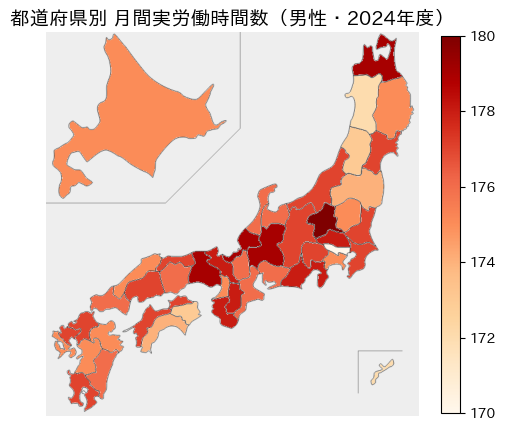

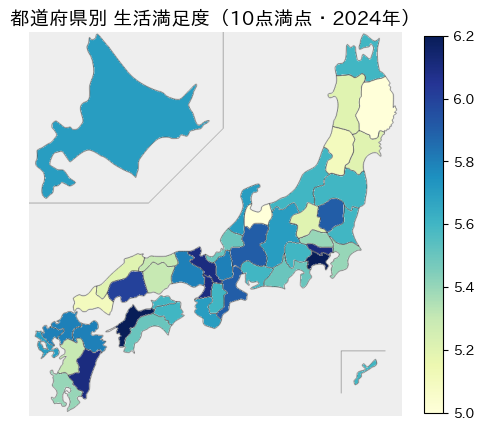

In [ ]:
draw_map(work_hours,   '都道府県別 月間実労働時間数（男性・2024年度）', 'OrRd')
draw_map(satisfaction, '都道府県別 生活満足度（10点満点・2024年）',   'YlGnBu')

## 5. Checking Correlation Using a Scatter Plot (散布図で相関を確認)

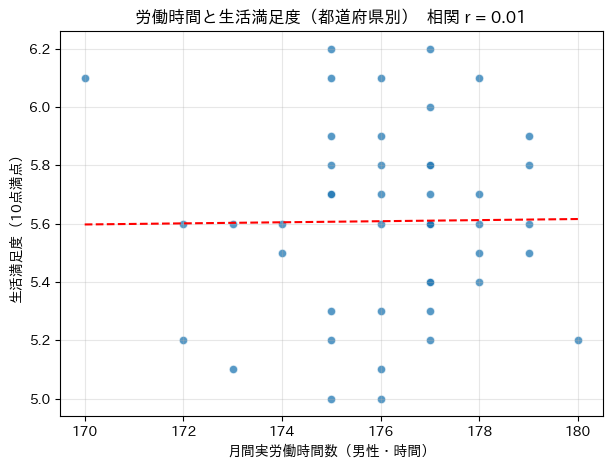

相関係数 r = 0.012


In [ ]:
import numpy as np
prefs = list(work_hours.keys())
x = [work_hours[p] for p in prefs]
y = [satisfaction[p] for p in prefs]
r = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=40, alpha=0.75, edgecolor='white')
z = np.polyfit(x, y, 1)
xs = np.array([min(x), max(x)])
ax.plot(xs, z[0]*xs + z[1], '--', color='red')
ax.set_xlabel('月間実労働時間数（男性・時間）')
ax.set_ylabel('生活満足度（10点満点）')
ax.set_title(f'労働時間と生活満足度（都道府県別）  相関 r = {r:.2f}')
ax.grid(alpha=0.3)
plt.show()
print(f'相関係数 r = {r:.3f}')